# Task 2: Toxicity Classification (Colab runner)

## Import dataset

In [4]:

import os, subprocess, sys
from pathlib import Path

REPO_URL = "https://github.com/ivant8k/IF5153-Chat-Moderation.git"
BRANCH = "feat/task-2"
DRIVE_JIGSAW = "/content/drive/MyDrive/tubes_nlp/jigsaw"      # folder berisi 3 csv Jigsaw
DRIVE_OUT = "/content/drive/MyDrive/tubes_nlp/task_2_runs"    # checkpoint + hasil (awet)

from google.colab import drive
drive.mount("/content/drive")
if not Path("/content/repo").exists():
    subprocess.run(["git", "clone", "-b", BRANCH, REPO_URL, "/content/repo"], check=True)
os.chdir("/content/repo")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "transformers", "scikit-learn", "pandas"], check=True)
Path("data/raw").mkdir(parents=True, exist_ok=True)
if not Path("data/raw/conda").exists():
    subprocess.run("git clone --depth 1 https://github.com/usydnlp/CONDA.git data/raw/conda && rm -rf data/raw/conda/.git", shell=True, check=True)
if not Path("data/raw/jigsaw").exists():
    os.symlink(DRIVE_JIGSAW, "data/raw/jigsaw")
Path(DRIVE_OUT).mkdir(parents=True, exist_ok=True)
Path("outputs/task_2").mkdir(parents=True, exist_ok=True)
if not Path("outputs/task_2/runs").exists():
    os.symlink(DRIVE_OUT, "outputs/task_2/runs")
!nvidia-smi | head -15

Mounted at /content/drive
Sun Nov 22 22:35:21 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------------

## 1. Data
Jigsaw + CONDA (split Task 1) + NoisyHate -> `data/processed/task_2`

In [5]:
!python src/task_2/prepare.py

jigsaw_train: 151592 | gate+ 0.101
jigsaw_dev: 7979 | gate+ 0.106
jigsaw_test: 63978 | gate+ 0.098
conda_train: 28965 baris | gate+ 0.192 | intent {'O': 21492, 'E': 3733, 'A': 1901, 'I': 1839}
conda_dev: 3500 baris | gate+ 0.204 | intent {'O': 2579, 'E': 505, 'I': 210, 'A': 206}
conda_bench: 3422 baris | gate+ 0.204 | intent {'O': 2532, 'E': 473, 'I': 225, 'A': 192}
conda_gold: 300 baris | gate+ 0.323
noisyhate: 1339 baris


Raw train.csv: 159,571
Comments with >=2 labels: 6.18%
Prepared splits total: 189,172
train: 127,898  (67.6%)
dev  :   6,743  (3.6%)
test :  54,531  (28.8%)


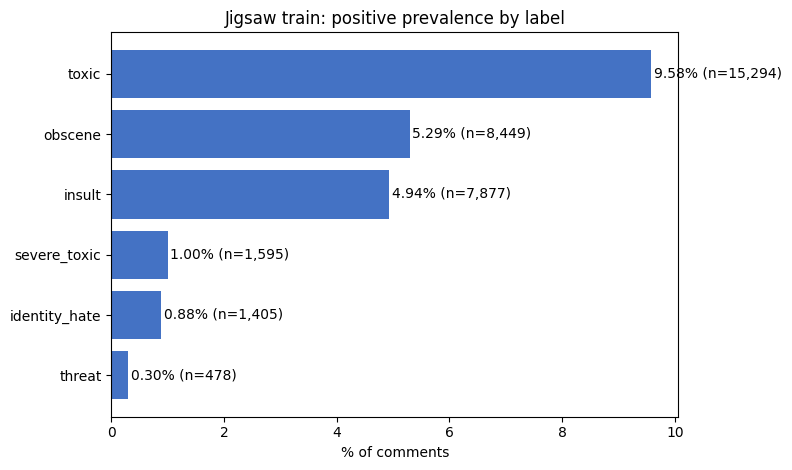

Saved: /content/drive/MyDrive/tubes_nlp/ppt_assets/jigsaw_eda.png


In [7]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

root = Path("/content/repo")
labels = ["toxic", "severe_toxic", "obscene", "threat", "insult", "identity_hate"]

jigsaw_raw = pd.read_csv(root / "data/raw/jigsaw/train.csv")
label_matrix = jigsaw_raw[labels].fillna(0).astype(int)

splits = {
    name: pd.read_csv(root / f"data/processed/task_2/jigsaw_{name}.tsv", sep="\t")
    for name in ["train", "dev", "test"]
}
total = sum(len(df) for df in splits.values())

print(f"Raw train.csv: {len(jigsaw_raw):,}")
print(f"Comments with >=2 labels: {(label_matrix.sum(axis=1) >= 2).mean() * 100:.2f}%")
print(f"Prepared splits total: {total:,}")
for name, df in splits.items():
    print(f"{name:5s}: {len(df):>7,}  ({len(df) / total * 100:.1f}%)")

counts = label_matrix.sum().sort_values()
rates = counts / len(jigsaw_raw) * 100

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(rates.index, rates.values, color="#4472C4")
ax.set_title("Jigsaw train: positive prevalence by label")
ax.set_xlabel("% of comments")

for y, label in enumerate(rates.index):
    ax.text(
        rates[label] + 0.05, y,
        f"{rates[label]:.2f}% (n={counts[label]:,})",
        va="center",
    )

fig.tight_layout()
out_dir = Path("/content/drive/MyDrive/tubes_nlp/ppt_assets")
out_dir.mkdir(parents=True, exist_ok=True)
out_path = out_dir / "jigsaw_eda.png"
fig.savefig(out_path, dpi=220, bbox_inches="tight")
plt.show()
print(f"Saved: {out_path}")

## 2. Baseline
E0 TF-IDF + LR dan zero-shot `unitary/toxic-bert`

In [3]:
!python src/task_2/baseline.py --run b0_tfidf
!python src/task_2/evaluate.py --run b0_tfidf
!python src/task_2/evaluate.py --run z_toxicbert --kind zeroshot

train 121221
  gate: 121221 baris, positif 26523
  toxic: 110077 baris, positif 14493
  severe_toxic: 110077 baris, positif 1506
  obscene: 110077 baris, positif 8010
  threat: 110077 baris, positif 460
  insult: 110077 baris, positif 7470
  identity_hate: 110077 baris, positif 1342
b0_tfidf conda_dev:norm: 3500 baris
b0_tfidf conda_dev:raw: 3500 baris
b0_tfidf conda_bench:norm: 3422 baris
b0_tfidf conda_bench:raw: 3422 baris
b0_tfidf conda_bench:t1pred: 3422 baris
b0_tfidf conda_gold:gold: 300 baris
b0_tfidf conda_gold:t1pred: 300 baris
b0_tfidf jigsaw_dev: 7979 baris
b0_tfidf jigsaw_test: 63978 baris
b0_tfidf noisyhate:perturbed: 1339 baris
b0_tfidf noisyhate:t1pred: 1339 baris
b0_tfidf noisyhate:clean: 1339 baris
set                conda_bench:norm  conda_bench:raw  conda_bench:t1pred  conda_dev:norm  conda_dev:raw  conda_gold:gold  conda_gold:t1pred  jigsaw_dev  jigsaw_test  noisyhate:clean  noisyhate:perturbed  noisyhate:t1pred
metric                                               

## 3. Arm DistilRoBERTa
E1 Jigsaw saja, E2 campuran (kandidat utama), E3 bertahap (Jigsaw lalu CONDA)

In [4]:
!python src/task_2/train.py --run e1_jigsaw --sources jigsaw
!python src/task_2/evaluate.py --run e1_jigsaw

e1_jigsaw | device cuda | train 63291 | positif gate 0.243
config.json: 100% 480/480 [00:00<00:00, 2.53MB/s]
tokenizer_config.json: 100% 25.0/25.0 [00:00<00:00, 148kB/s]
vocab.json: 100% 899k/899k [00:00<00:00, 13.7MB/s]
merges.txt: 100% 456k/456k [00:00<00:00, 13.4MB/s]
tokenizer.json: 100% 1.36M/1.36M [00:00<00:00, 20.2MB/s]

model.safetensors: downloading bytes:  80% 263M/331M [00:01<00:00, 373MB/s, 20.8MB/s  ]
model.safetensors: downloading bytes:  95% 314M/331M [00:01<00:00, 319MB/s, 27.1MB/s  ]
model.safetensors: downloading bytes: 100% 314M/314M [00:01<00:00, 180MB/s, 29.3MB/s  ]
model.safetensors: reconstructing file: 100% 331M/331M [00:01<00:00, 190MB/s, 31.4MB/s  ]
Loading weights: 100% 103/103 [00:00<00:00, 4245.04it/s]
[transformers] RobertaModel LOAD REPORT from: distilroberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.

In [5]:
!python src/task_2/train.py --run e2_mix --sources jigsaw,conda
!python src/task_2/evaluate.py --run e2_mix

e2_mix | device cuda | train 121221 | positif gate 0.219
Loading weights: 100% 103/103 [00:00<00:00, 15523.30it/s]
[transformers] RobertaModel LOAD REPORT from: distilroberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
  ep1 step 200/3789 loss 0.4999 (97s)
  ep1 step 400/3789 loss 0.3513 (195s)
  ep1 step 600/3789 loss 0.2953 (293s)
  ep1 step 800/3789 loss 0.2621 (391s)
  ep1 step 1000/3789 loss 0.2405 (490s)
  ep1 step 1200/3789 loss 0.2252 (588s)
  ep1 step 1400/3789 loss 0.2148 (686s)
  ep1 step 1600/3789 loss 0.2053 (784s)
  ep1 step 1800/3789 loss 0.1981 (883s)
  ep1 step 2000/3789 loss 0.1

In [11]:
!python src/task_2/train.py --run e3_seq --sources conda --init-from e1_jigsaw --lr 1e-5 --select all
!python src/task_2/evaluate.py --run e3_seq

e3_seq | device cuda | train 57930 | positif gate 0.192
  ep1 step 200/1811 loss 0.1006 (21s)
  ep1 step 400/1811 loss 0.0700 (44s)
  ep1 step 600/1811 loss 0.0576 (65s)
  ep1 step 800/1811 loss 0.0510 (87s)
  ep1 step 1000/1811 loss 0.0470 (108s)
  ep1 step 1200/1811 loss 0.0442 (129s)
  ep1 step 1400/1811 loss 0.0420 (151s)
  ep1 step 1600/1811 loss 0.0403 (172s)
  ep1 step 1800/1811 loss 0.0390 (193s)
{'epoch': 1, 'train_loss': 0.03889352041975482, 'score': 0.7953196110523102, 'conda_gate_ap': 0.946076221819225, 'jigsaw_cat_ap': 0.6445630002853955}
  ep2 step 200/1811 loss 0.0269 (251s)
  ep2 step 400/1811 loss 0.0258 (273s)
  ep2 step 600/1811 loss 0.0249 (294s)
  ep2 step 800/1811 loss 0.0247 (315s)
  ep2 step 1000/1811 loss 0.0246 (336s)
  ep2 step 1200/1811 loss 0.0243 (357s)
  ep2 step 1400/1811 loss 0.0243 (379s)
  ep2 step 1600/1811 loss 0.0242 (400s)
  ep2 step 1800/1811 loss 0.0240 (421s)
{'epoch': 2, 'train_loss': 0.023994619305572645, 'score': 0.7966127486115437, 'conda_g

## 4. Ringkasan

In [6]:
!python src/task_2/summary.py

                                     b0_tfidf  e1_jigsaw  e2_mix  z_toxicbert
conda_bench:norm|gate_ap                0.893      0.660   0.902        0.675
conda_bench:norm|balanced_f1            0.842      0.616   0.849        0.638
conda_bench:norm|balanced_macro_f1      0.902      0.766   0.906        0.779
conda_bench:norm|balanced_fpr_A         0.026      0.021   0.010        0.021
conda_bench:norm|balanced_fpr_O         0.033      0.057   0.036        0.058
conda_bench:norm|balanced_recall_E      0.886      0.748   0.884        0.799
conda_bench:norm|balanced_recall_I      0.680      0.102   0.733        0.089
conda_bench:norm|strict_precision       0.935      0.944   0.932        0.947
conda_bench:norm|strict_recall          0.705      0.120   0.705        0.178
conda_bench:raw|balanced_f1             0.835      0.604   0.850        0.629
conda_bench:t1pred|balanced_f1          0.842      0.612   0.851        0.638
conda_gold:gold|gate_ap                 0.839      0.772   0.859

## 5. Demo kontrak output

In [7]:
import sys
sys.path.insert(0, "src/task_2")
from predict import ToxicityClassifier
import json
clf = ToxicityClassifier("e2_mix", mode="balanced")
for r in clf.classify(["you are idiot", "gg wp", "report mid he is feeding", "u | r | trash | noob"]):
    print(json.dumps(r, indent=1))

{
 "text": "you are idiot",
 "p_toxic": 0.9955,
 "trigger": true,
 "labels": {
  "toxic": 0.9855,
  "severe_toxic": 0.133,
  "obscene": 0.8597,
  "threat": 0.0027,
  "insult": 0.9909,
  "identity_hate": 0.0373
 },
 "warnings": [
  "insult",
  "obscene"
 ],
 "message": "Warning: your message contains insults and obscene language.",
 "mode": "balanced",
 "threshold": 0.4417
}
{
 "text": "gg wp",
 "p_toxic": 0.0011,
 "trigger": false,
 "labels": {
  "toxic": 0.0006,
  "severe_toxic": 0.0006,
  "obscene": 0.0007,
  "threat": 0.001,
  "insult": 0.0006,
  "identity_hate": 0.0006
 },
 "warnings": [],
 "message": null,
 "mode": "balanced",
 "threshold": 0.4417
}
{
 "text": "report mid he is feeding",
 "p_toxic": 0.0619,
 "trigger": false,
 "labels": {
  "toxic": 0.0006,
  "severe_toxic": 0.0007,
  "obscene": 0.0006,
  "threat": 0.0009,
  "insult": 0.0008,
  "identity_hate": 0.0005
 },
 "warnings": [],
 "message": null,
 "mode": "balanced",
 "threshold": 0.4417
}
{
 "text": "u | r | trash | noo

In [8]:
from pathlib import Path

run_dir = Path("/content/drive/MyDrive/tubes_nlp/task_2_runs/e2_mix")
required = [
    "DONE",
    "config.json",
    "thresholds.json",
    "metrics.tsv",
    "checkpoints/best/model.pt",
    "checkpoints/best/config.json",
    "checkpoints/best/tokenizer_config.json",
]

for item in required:
    path = run_dir / item
    print(("OK      " if path.is_file() else "MISSING "), path)

OK       /content/drive/MyDrive/tubes_nlp/task_2_runs/e2_mix/DONE
OK       /content/drive/MyDrive/tubes_nlp/task_2_runs/e2_mix/config.json
OK       /content/drive/MyDrive/tubes_nlp/task_2_runs/e2_mix/thresholds.json
OK       /content/drive/MyDrive/tubes_nlp/task_2_runs/e2_mix/metrics.tsv
OK       /content/drive/MyDrive/tubes_nlp/task_2_runs/e2_mix/checkpoints/best/model.pt
OK       /content/drive/MyDrive/tubes_nlp/task_2_runs/e2_mix/checkpoints/best/config.json
OK       /content/drive/MyDrive/tubes_nlp/task_2_runs/e2_mix/checkpoints/best/tokenizer_config.json


In [9]:
from pathlib import Path
from zipfile import ZipFile, ZIP_STORED
import hashlib

run_dir = Path("/content/drive/MyDrive/tubes_nlp/task_2_runs/e2_mix")
release_dir = Path("/content/drive/MyDrive/tubes_nlp/releases")
release_dir.mkdir(parents=True, exist_ok=True)

archive = release_dir / "task2-e2-mix-v1.0.zip"

with ZipFile(archive, "w", ZIP_STORED) as zf:
    for path in run_dir.rglob("*"):
        relative = path.relative_to(run_dir)
        if path.is_file() and "probs" not in relative.parts:
            zf.write(path, Path("e2_mix") / relative)

digest = hashlib.sha256(archive.read_bytes()).hexdigest()
print("Paket:", archive)
print("Ukuran:", f"{archive.stat().st_size / (1024**2):.1f} MB")
print("SHA-256:", digest)

Paket: /content/drive/MyDrive/tubes_nlp/releases/task2-e2-mix-v1.0.zip
Ukuran: 316.7 MB
SHA-256: 43603835702efc9938efac7565cad49785c970ef25f36201dd27ca3f04e091cf


In [10]:
from zipfile import ZipFile

archive = "/content/drive/MyDrive/tubes_nlp/releases/task2-e2-mix-v1.0.zip"
required = [
    "e2_mix/thresholds.json",
    "e2_mix/config.json",
    "e2_mix/metrics.tsv",
    "e2_mix/checkpoints/best/model.pt",
    "e2_mix/checkpoints/best/config.json",
    "e2_mix/checkpoints/best/tokenizer_config.json",
]

with ZipFile(archive) as zf:
    names = set(zf.namelist())
    missing = [name for name in required if name not in names]
    has_probs = any("/probs/" in name for name in names)
    bad_file = zf.testzip()

print("Berkas yang hilang:", missing)
print("Folder probs ikut masuk:", has_probs)
print("ZIP rusak pada:", bad_file)
print("Jumlah berkas:", len(names))

Berkas yang hilang: []
Folder probs ikut masuk: False
ZIP rusak pada: None
Jumlah berkas: 10
